<a href="https://colab.research.google.com/github/Bhavesh1412/CSL701-CS33_Machine-Learning-Lab/blob/main/Experiment_9_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name : Bhavesh Chandrakant Mundye

Batch : CS02


Roll Number : CS33



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [21]:
# Task 1: Import All Required Libraries and Upload Dataset

# Data handling
import pandas as pd
import numpy as np
import io

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Google Colab file upload
from google.colab import files

# Machine learning: splitting, preprocessing, and models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression

# Evaluation metrics and confusion matrix visualization
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Upload the dataset CSV from your computer
uploaded = files.upload()

csv_files = [
    filename for filename in uploaded.keys()
    if filename.lower().endswith(".csv")
]

if not csv_files:
    raise ValueError("No CSV file uploaded. Please upload your dataset as a .csv file.")

# Load the first uploaded CSV
df = pd.read_csv(io.BytesIO(uploaded[csv_files[0]]))

print("Dataset loaded:", csv_files[0])
print("Dataset shape:", df.shape)
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Saving palmerpenguins_extended.csv to palmerpenguins_extended (4).csv
Dataset loaded: palmerpenguins_extended (4).csv
Dataset shape: (3430, 11)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,diet,life_stage,health_metrics,year
0,Adelie,Biscoe,53.4,17.8,219.0,5687.0,female,fish,adult,overweight,2021
1,Adelie,Biscoe,49.3,18.1,245.0,6811.0,female,fish,adult,overweight,2021
2,Adelie,Biscoe,55.7,16.6,226.0,5388.0,female,fish,adult,overweight,2021
3,Adelie,Biscoe,38.0,15.6,221.0,6262.0,female,fish,adult,overweight,2021
4,Adelie,Biscoe,60.7,17.9,177.0,4811.0,female,fish,juvenile,overweight,2021



Column names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'diet', 'life_stage', 'health_metrics', 'year']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3430 entries, 0 to 3429
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            3430 non-null   object 
 1   island             3430 non-null   object 
 2   bill_length_mm     3430 non-null   float64
 3   bill_depth_mm      3430 non-null   float64
 4   flipper_length_mm  3430 non-null   float64
 5   body_mass_g        3430 non-null   float64
 6   sex                3430 non-null   object 
 7   diet               3430 non-null   object 
 8   life_stage         3430 non-null   object 
 9   health_metrics     3430 non-null   object 
 10  year               3430 non-null   int64  
dtypes: float64(4), int64(1), object(6)
memory usage: 294.9+ KB


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [22]:
# Task 2: Select Features and Target & Preprocess

# Normalize column names for easier matching (supports common naming variations).
column_lookup = {str(col).strip().lower().replace(" ", "_"): col for col in df.columns}

def find_column(possible_names):
    for name in possible_names:
        key = name.lower().strip().replace(" ", "_")
        if key in column_lookup:
            return column_lookup[key]
    return None

species_col = find_column(["species", "penguin_species", "target", "class"])
feature_candidates = {
    "culmen_length_mm": ["culmen_length_mm", "bill_length_mm"],
    "culmen_depth_mm": ["culmen_depth_mm", "bill_depth_mm"],
    "flipper_length_mm": ["flipper_length_mm", "flipper_length"],
    "body_mass_g": ["body_mass_g", "body_mass", "body_mass_grams"]
}

if species_col is None:
    raise ValueError(f"Could not find the species/target column. Available columns: {df.columns.tolist()}")

selected_columns = {}
missing_features = []
for standard_name, alternatives in feature_candidates.items():
    actual = find_column(alternatives)
    if actual is None:
        missing_features.append(standard_name)
    else:
        selected_columns[standard_name] = actual

if missing_features:
    raise ValueError(
        f"Could not find these required numeric features: {missing_features}. "
        f"Available columns: {df.columns.tolist()}"
    )

# Create a clean dataframe using consistent feature names.
data = pd.DataFrame({
    standard_name: pd.to_numeric(df[actual_col], errors="coerce")
    for standard_name, actual_col in selected_columns.items()
})
data["species"] = df[species_col].astype("string").str.strip()

# Replace blank/unknown target labels and remove rows missing any required value.
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=list(feature_candidates.keys()) + ["species"])
data = data[data["species"] != ""]

# Encode target labels.
label_encoder = LabelEncoder()
data["species_encoded"] = label_encoder.fit_transform(data["species"])

feature_names = list(feature_candidates.keys())
X = data[feature_names]
y = data["species_encoded"]
class_names = label_encoder.classes_

print("Rows after removing missing/invalid values:", len(data))
print("Features:", feature_names)
print("Target classes:", list(class_names))
display(data.head())
print("\nClass distribution:")
print(data["species"].value_counts())


Rows after removing missing/invalid values: 3430
Features: ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
Target classes: ['Adelie', 'Chinstrap', 'Gentoo']


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,species,species_encoded
0,53.4,17.8,219.0,5687.0,Adelie,0
1,49.3,18.1,245.0,6811.0,Adelie,0
2,55.7,16.6,226.0,5388.0,Adelie,0
3,38.0,15.6,221.0,6262.0,Adelie,0
4,60.7,17.9,177.0,4811.0,Adelie,0



Class distribution:
species
Adelie       1560
Gentoo       1247
Chinstrap     623
Name: count, dtype: Int64


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [23]:
# Task 3: Split the Data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 2744
Testing samples: 686


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [24]:
# Task 4: Implement CART Classifier
cart_model = DecisionTreeClassifier(
    criterion="gini",   # CART commonly uses Gini impurity for classification
    random_state=42
)
cart_model.fit(X_train, y_train)

y_pred_cart = cart_model.predict(X_test)
print("CART model trained successfully.")


CART model trained successfully.


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Accuracy: 0.4519 (45.19%)


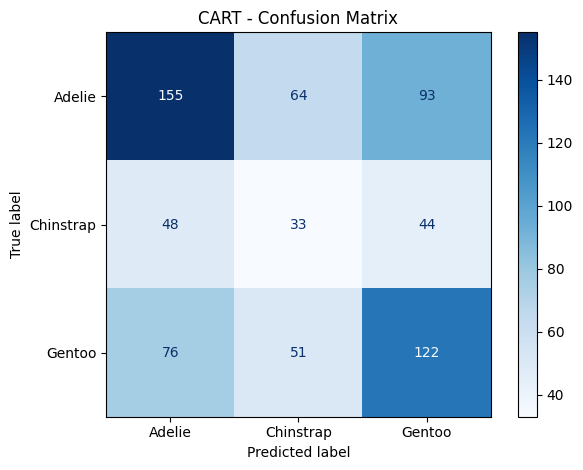

CART Classification Report:
              precision    recall  f1-score   support

      Adelie       0.56      0.50      0.52       312
   Chinstrap       0.22      0.26      0.24       125
      Gentoo       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686



In [25]:
# Task 5: Evaluate CART Model
cart_accuracy = accuracy_score(y_test, y_pred_cart)
print(f"CART Accuracy: {cart_accuracy:.4f} ({cart_accuracy * 100:.2f}%)")

cart_cm = confusion_matrix(y_test, y_pred_cart)
ConfusionMatrixDisplay(
    confusion_matrix=cart_cm,
    display_labels=class_names
).plot(cmap="Blues", values_format="d")
plt.title("CART - Confusion Matrix")
plt.tight_layout()
plt.show()

print("CART Classification Report:")
print(classification_report(
    y_test, y_pred_cart,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))


# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


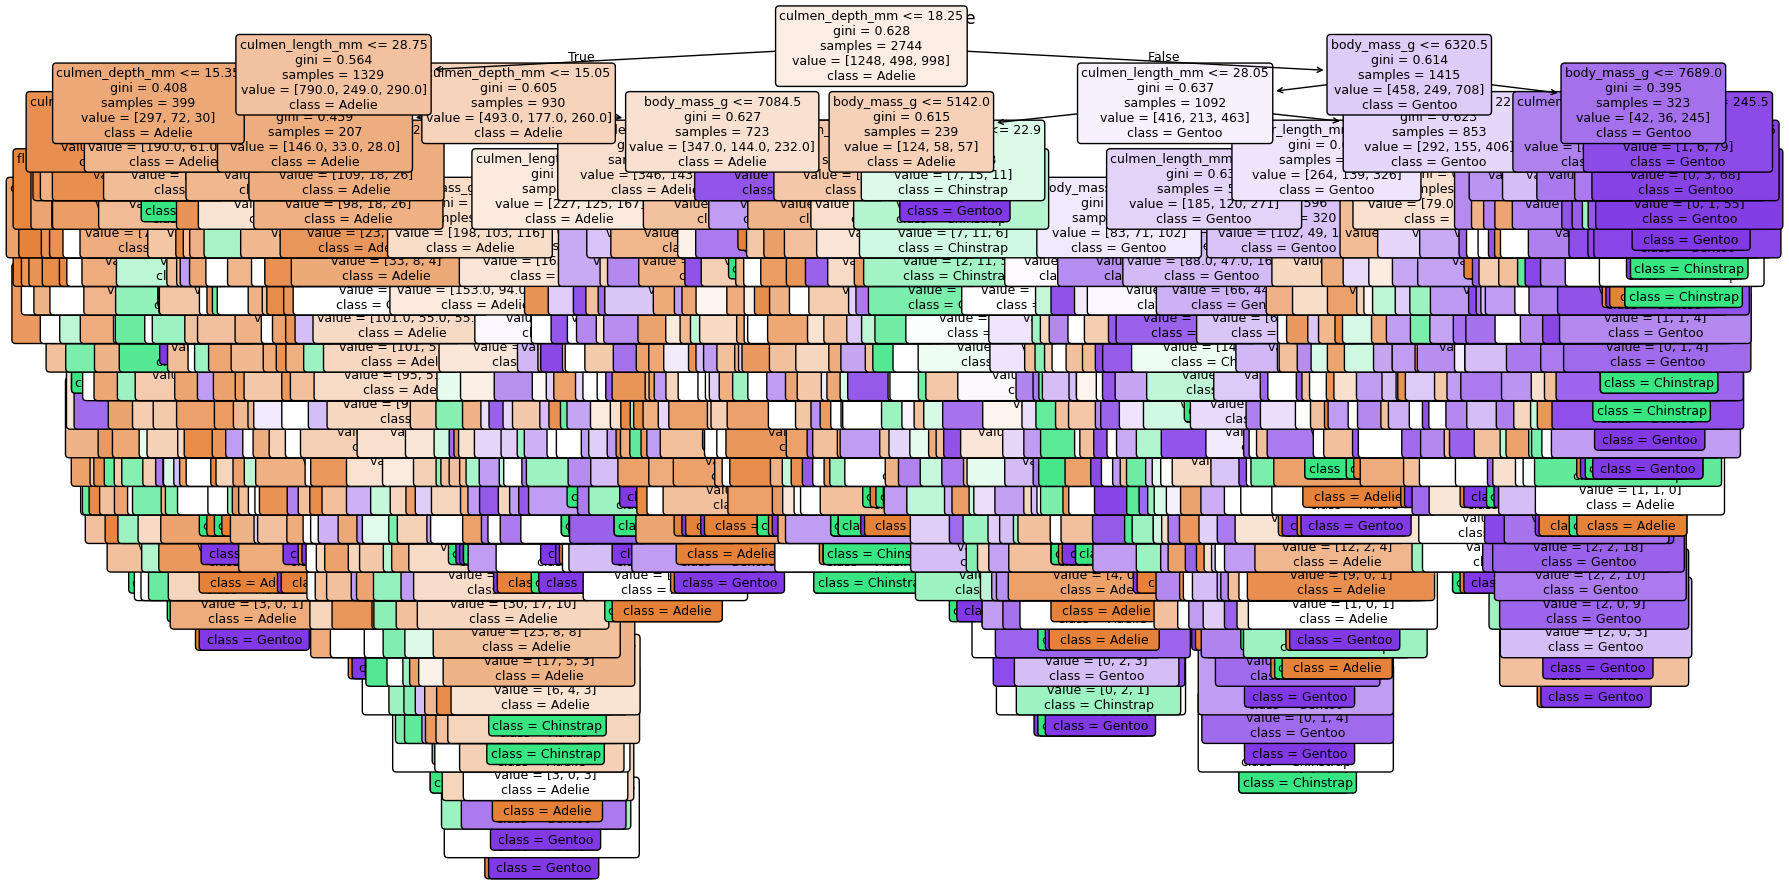

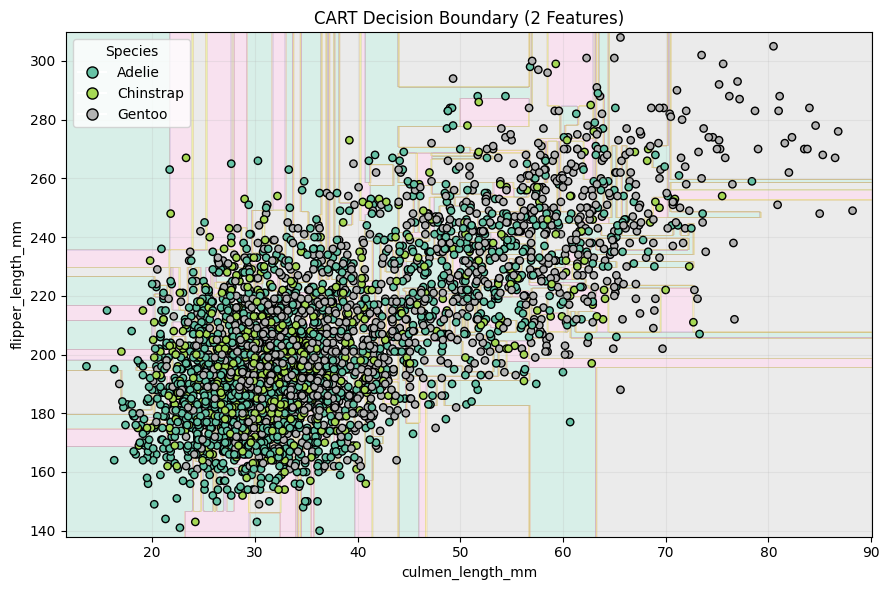

2-feature CART accuracy: 0.4388


In [26]:
# Task 6: Visualize Decision Tree & Decision Boundary

plt.figure(figsize=(18, 9))
plot_tree(
    cart_model,
    feature_names=feature_names,
    class_names=list(class_names),
    filled=True,
    rounded=True,
    impurity=True,
    proportion=False,
    fontsize=9
)
plt.title("CART Decision Tree")
plt.tight_layout()
plt.show()

# Train a separate CART model using the two features required for 2-D visualization.
features_2d = ["culmen_length_mm", "flipper_length_mm"]
X2 = data[features_2d]
y_all = data["species_encoded"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y_all, test_size=0.20, random_state=42, stratify=y_all
)

cart_2d = DecisionTreeClassifier(criterion="gini", random_state=42)
cart_2d.fit(X2_train, y2_train)

def plot_decision_boundary(ax, model, X_plot, y_plot, title, feature_x, feature_y, mesh_step=0.25):
    x_min, x_max = X_plot[feature_x].min() - 2, X_plot[feature_x].max() + 2
    y_min, y_max = X_plot[feature_y].min() - 2, X_plot[feature_y].max() + 2
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, mesh_step),
        np.arange(y_min, y_max, mesh_step)
    )
    grid = pd.DataFrame({feature_x: xx.ravel(), feature_y: yy.ravel()})
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25, cmap=plt.cm.Set2)
    scatter = ax.scatter(
        X_plot[feature_x], X_plot[feature_y],
        c=y_plot, cmap=plt.cm.Set2, edgecolor="black", s=28
    )
    ax.set_xlabel(feature_x)
    ax.set_ylabel(feature_y)
    ax.set_title(title)
    ax.grid(alpha=0.2)
    return scatter

fig, ax = plt.subplots(figsize=(9, 6))
plot_decision_boundary(
    ax, cart_2d, X2, y_all,
    "CART Decision Boundary (2 Features)",
    features_2d[0], features_2d[1]
)
handles, _ = ax.get_legend_handles_labels()
legend_handles = []
for i, name in enumerate(class_names):
    legend_handles.append(plt.Line2D(
        [0], [0], marker="o", color="w", label=name,
        markerfacecolor=plt.cm.Set2(i / max(1, len(class_names)-1)),
        markeredgecolor="black", markersize=8
    ))
ax.legend(handles=legend_handles, title="Species")
plt.tight_layout()
plt.show()

print(f"2-feature CART accuracy: {accuracy_score(y2_test, cart_2d.predict(X2_test)):.4f}")


# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

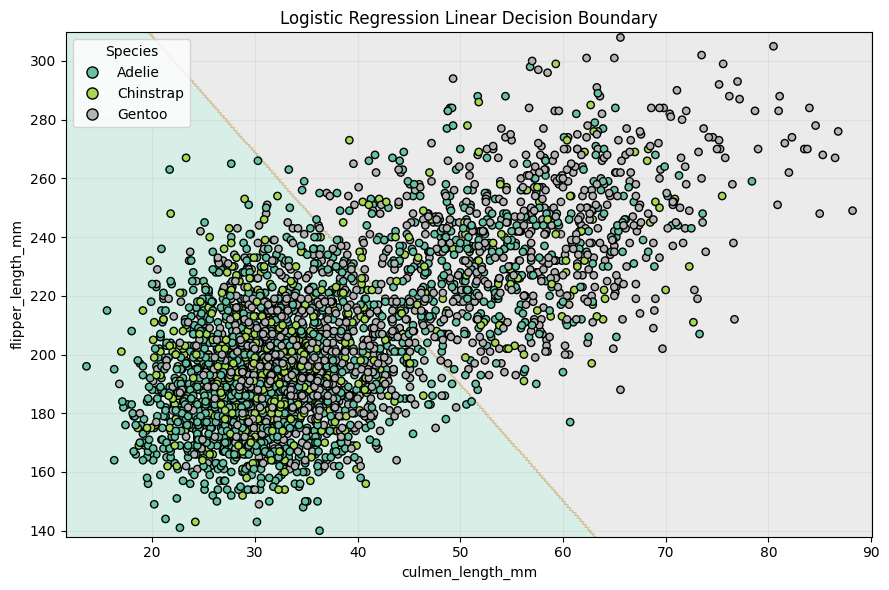

In [27]:
# Task 7: Normal Linear Classification Boundary (Logistic Regression)

# Standardize the two features for Logistic Regression.
scaler_2d = StandardScaler()
X2_train_scaled = scaler_2d.fit_transform(X2_train)
X2_test_scaled = scaler_2d.transform(X2_test)

logistic_model = LogisticRegression(max_iter=2000, random_state=42)
logistic_model.fit(X2_train_scaled, y2_train)
y_pred_logistic_2d = logistic_model.predict(X2_test_scaled)

# Helper to plot the linear model boundary in original feature units.
def plot_logistic_boundary(ax, model, scaler, X_plot, y_plot, title, feature_x, feature_y, mesh_step=0.25):
    x_min, x_max = X_plot[feature_x].min() - 2, X_plot[feature_x].max() + 2
    y_min, y_max = X_plot[feature_y].min() - 2, X_plot[feature_y].max() + 2
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, mesh_step),
        np.arange(y_min, y_max, mesh_step)
    )
    grid = pd.DataFrame({feature_x: xx.ravel(), feature_y: yy.ravel()})
    grid_scaled = scaler.transform(grid)
    Z = model.predict(grid_scaled).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25, cmap=plt.cm.Set2)
    ax.scatter(
        X_plot[feature_x], X_plot[feature_y],
        c=y_plot, cmap=plt.cm.Set2, edgecolor="black", s=28
    )
    ax.set_xlabel(feature_x)
    ax.set_ylabel(feature_y)
    ax.set_title(title)
    ax.grid(alpha=0.2)

fig, ax = plt.subplots(figsize=(9, 6))
plot_logistic_boundary(
    ax, logistic_model, scaler_2d, X2, y_all,
    "Logistic Regression Linear Decision Boundary",
    features_2d[0], features_2d[1]
)
legend_handles = [
    plt.Line2D([0], [0], marker="o", color="w", label=name,
               markerfacecolor=plt.cm.Set2(i / max(1, len(class_names)-1)),
               markeredgecolor="black", markersize=8)
    for i, name in enumerate(class_names)
]
ax.legend(handles=legend_handles, title="Species")
plt.tight_layout()
plt.show()


# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

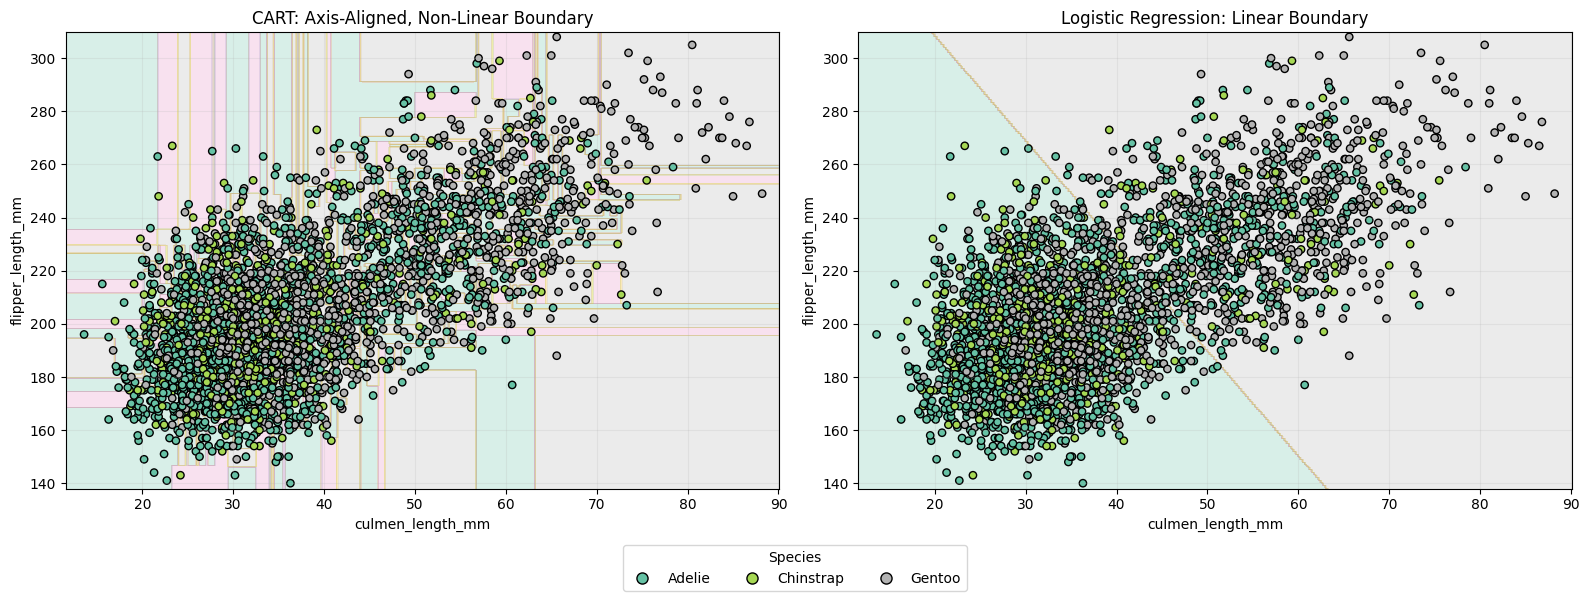

CART creates rectangular, axis-aligned regions.
Logistic Regression creates linear class boundaries (straight decision surfaces).


In [28]:
# Task 8: Compare CART and Logistic Regression Decision Boundaries

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_decision_boundary(
    axes[0], cart_2d, X2, y_all,
    "CART: Axis-Aligned, Non-Linear Boundary",
    features_2d[0], features_2d[1]
)
plot_logistic_boundary(
    axes[1], logistic_model, scaler_2d, X2, y_all,
    "Logistic Regression: Linear Boundary",
    features_2d[0], features_2d[1]
)

legend_handles = [
    plt.Line2D([0], [0], marker="o", color="w", label=name,
               markerfacecolor=plt.cm.Set2(i / max(1, len(class_names)-1)),
               markeredgecolor="black", markersize=8)
    for i, name in enumerate(class_names)
]
fig.legend(handles=legend_handles, title="Species", loc="lower center", ncol=len(class_names))
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

print("CART creates rectangular, axis-aligned regions.")
print("Logistic Regression creates linear class boundaries (straight decision surfaces).")


# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

Accuracy Comparison:


,Model,Accuracy
0,CART Decision Tree (2 features),0.438776
1,Logistic Regression (2 features),0.526239



CART (2 features) Confusion Matrix:


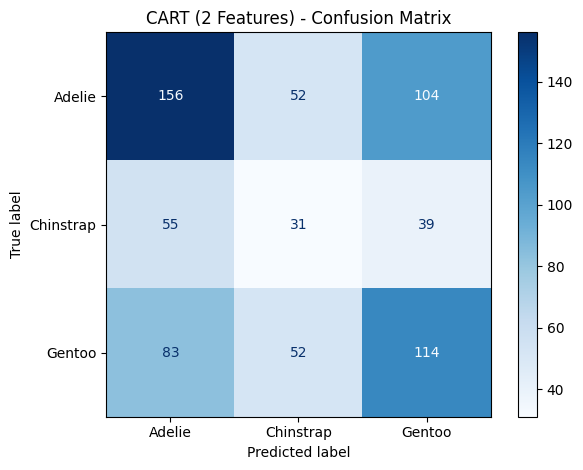

CART (2 features) Classification Report:
              precision    recall  f1-score   support

      Adelie       0.53      0.50      0.51       312
   Chinstrap       0.23      0.25      0.24       125
      Gentoo       0.44      0.46      0.45       249

    accuracy                           0.44       686
   macro avg       0.40      0.40      0.40       686
weighted avg       0.44      0.44      0.44       686


Logistic Regression Confusion Matrix:


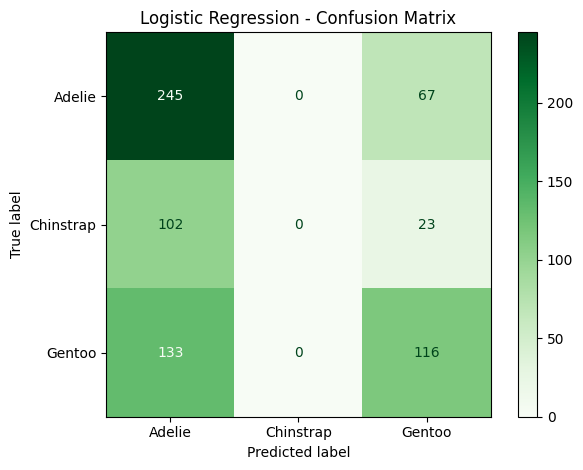

Logistic Regression Classification Report:
              precision    recall  f1-score   support

      Adelie       0.51      0.79      0.62       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.56      0.47      0.51       249

    accuracy                           0.53       686
   macro avg       0.36      0.42      0.38       686
weighted avg       0.44      0.53      0.47       686


Conclusion: Logistic Regression performed better on this test split by 8.75 percentage points.


In [29]:
# Task 9: Compare Performance of CART and Logistic Regression

# Evaluate Logistic Regression using the same two-feature train/test split.
logistic_accuracy = accuracy_score(y2_test, y_pred_logistic_2d)
cart_2d_pred = cart_2d.predict(X2_test)
cart_2d_accuracy = accuracy_score(y2_test, cart_2d_pred)

comparison = pd.DataFrame({
    "Model": ["CART Decision Tree (2 features)", "Logistic Regression (2 features)"],
    "Accuracy": [cart_2d_accuracy, logistic_accuracy]
})
print("Accuracy Comparison:")
display(comparison)

print("\nCART (2 features) Confusion Matrix:")
ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y2_test, cart_2d_pred, labels=np.arange(len(class_names))),
    display_labels=class_names
).plot(cmap="Blues", values_format="d")
plt.title("CART (2 Features) - Confusion Matrix")
plt.tight_layout()
plt.show()

print("CART (2 features) Classification Report:")
print(classification_report(
    y2_test, cart_2d_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

print("\nLogistic Regression Confusion Matrix:")
ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y2_test, y_pred_logistic_2d, labels=np.arange(len(class_names))),
    display_labels=class_names
).plot(cmap="Greens", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

print("Logistic Regression Classification Report:")
print(classification_report(
    y2_test, y_pred_logistic_2d,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

if cart_2d_accuracy > logistic_accuracy:
    print(f"\nConclusion: CART performed better on this test split by {(cart_2d_accuracy-logistic_accuracy)*100:.2f} percentage points.")
elif logistic_accuracy > cart_2d_accuracy:
    print(f"\nConclusion: Logistic Regression performed better on this test split by {(logistic_accuracy-cart_2d_accuracy)*100:.2f} percentage points.")
else:
    print("\nConclusion: Both models achieved the same accuracy on this test split.")


# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.